<a href="https://colab.research.google.com/github/Mateus-cpa/Analise-bairros-de-Curitiba/blob/main/An%C3%A1lise_imobili%C3%A1ria_em_Curitiba.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importações de bibliotecas

In [264]:
import io
import os

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from google.colab import userdata
import urllib.request



#Carga de dados

## Dados do site guru dos imóveis

In [265]:

# Baixar csv
path_guru = 'https://gurudosimoveis.com.br/dados/curitiba-pr.csv'

# Criando uma requisição com User-Agent para evitar o erro 403 Forbidden
req = urllib.request.Request(
    path_guru,
    headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36'}
)

try:
    with urllib.request.urlopen(req) as response:
        csv_data = response.read()
    # Carregando no pandas
    imoveis_df = pandas.read_csv(io.BytesIO(csv_data), header=1)
    display(imoveis_df.sample(10))
except Exception as e:
    print("Erro ao carregar os dados:", e)

imoveis_df.bairro.unique()

,mes,bairro,transacao,mediana_m2,p25_m2,p75_m2,anuncios_ativos_media_dia,novos_anuncios,dias_no_mercado_medio
1928,2026-10,Tarumã,venda,8085.0,7356.0,8510.0,12,2,590.0
240,2025-10,Prado Velho,aluguel,80.0,80.0,80.0,17,1,1060.0
1249,2026-05,Xaxim,venda,6029.0,5073.0,6792.0,147,6,444.0
35,2025-09,Cabral,aluguel,71.0,71.0,72.0,5,0,74.0
150,2025-10,Alto da XV,venda,9936.0,9186.0,11256.0,20,4,541.0
1818,2026-10,Bairro Alto,venda,5783.0,5158.0,6584.0,117,10,478.0
1722,2026-09,Ecoville,venda,12296.0,10425.0,14475.0,204,6,432.0
1125,2026-05,Atuba,aluguel,26.0,26.0,26.0,3,0,1006.0
73,2025-09,Hugo Lange,venda,11435.0,8036.0,12925.0,24,0,396.0
1808,2026-10,Alto da Rua XV,venda,12946.0,10937.0,14563.0,51,2,449.0


array(['Abranches', 'Água Verde', 'Ahú', 'Alto Boqueirão',
       'Alto da Glória', 'Alto da Rua XV', 'Alto da XV', 'Atuba',
       'Augusta', 'Bacacheri', 'Bairro Alto', 'Bairro Seminário',
       'Barigui', 'Barreirinha', 'Batel', 'Bigorrilho', 'Boa Vista',
       'Bom Retiro', 'Boqueirão', 'Butiatuvinha', 'Cabral', 'Cachoeira',
       'Cajuru', 'Campina do Siqueira', 'Campo Comprido',
       'Campo de Santana', 'Capão da Imbuia', 'Capão Raso', 'Cascatinha',
       'Centro', 'Centro Cívico', 'Champagnat', 'Cidade Industrial',
       'Cidade Industrial de Curitiba', 'Cristo Rei', 'Ecoville', 'Fanny',
       'Fazendinha', 'Ganchinho', 'Guabirotuba', 'Guaíra', 'Hauer',
       'Hugo Lange', 'Jardim Botânico', 'Jardim das Américas',
       'Jardim Social', 'Juvevê', 'Lindóia', 'Mercês', 'Mossunguê',
       'Neoville', 'Novo Mundo', 'Orleans', 'Parolin', 'Pilarzinho',
       'Pinheirinho', 'Portão', 'Prado Velho', 'Rebouças', 'Riviera',
       'Santa Cândida', 'Santa Felicidade', 'Santa Qu

## Tratar bairros com nomes diferentes


In [266]:
imoveis_df['bairro'] = imoveis_df['bairro'].replace({
    'Alto da XV': 'Alto da Rua XV',
    'Alto XV': 'Alto da Rua XV',
    'Ecovile': 'Ecoville',
    'Monssunguê': 'Mossunguê'
})

## Adicionando Regionais

As 10 Regionais Administrativas de Curitiba são:

- Matriz: Região central, histórica e comercial (inclui Centro, Batel, Bigorrilho, Mercês, entre outros).
- Santa Felicidade: Conhecida pela herança italiana e gastronomia (Santa Felicidade, Vista Alegre, Orleans, etc.).
- Boa Vista: Localizada no setor norte (Cabral, Juvevê, Bacacheri, Boa Vista, Santa Cândida, etc.).
- Cajuru: Na zona leste (Cajuru, Uberaba, Jardim das Américas, Tarumã).
- Boqueirão: Na zona sul-leste (Boqueirão, Hauer, Xaxim, Alto Boqueirão).
- Pinheirinho: Na zona sul (Pinheirinho, Tindiqüera/Capão Raso, Fanny, Lindóia).
- Bairro Novo: Na zona sul/extremidade (Sítio Cercado, Ganchinho, Bairro Tatuquara/New areas).
- Tatuquara: Região sul mais recente (Tatuquara, Campo de Santana, Caximba).
- Fazendinha / Portão: Zona oeste/sudoeste (Portão, Fazendinha, Campo Comprido, Santa Quitéria).
- CIC (Cidade Industrial de Curitiba): Zona oeste/sul (CIC, Augusta, Riviera)


![Regionais](https://upload.wikimedia.org/wikipedia/commons/8/8f/Regionais_Curitiba.jpg?utm_source=pt.wikipedia.org&utm_campaign=index&utm_content=original)

In [269]:
regionais = {
    'Abranches': 'Boa Vista',
    'Água Verde': 'Fazendinha / Portão',
    'Ahú': 'Matriz',
    'Alto Boqueirão': 'Boqueirão',
    'Alto da Glória': 'Matriz',
    'Alto da Rua XV': 'Matriz',
    'Alto da XV': 'Matriz',
    'Alto Xv': 'Matriz',
    'Atuba': 'Boa Vista',
    'Augusta': 'CIC',
    'Bacacheri': 'Boa Vista',
    'Bairro Alto': 'Boa Vista',
    'Bairro Seminário': 'Matriz',
    'Seminário': 'Matriz',
    'Barigui': 'Santa Felicidade',
    'Barreirinha': 'Boa Vista',
    'Batel': 'Matriz',
    'Bigorrilho': 'Matriz',
    'Butiatuvinha': 'Santa Felicidade',
    'Champagnat': 'Matriz',
    'Boa Vista': 'Boa Vista',
    'Bom Retiro': 'Matriz',
    'Boqueirão': 'Boqueirão',
    'Butiatuvinha': 'Santa Felicidade',
    'Cabral': 'Matriz',
    'Cachoeira': 'Boa Vista',
    'Cajuru': 'Cajuru',
    'Campina do Siqueira': 'Santa Felicidade',
    'Campo Comprido': 'Santa Felicidade',
    'Campo de Santana': 'Tatuquara',
    'Capão da Imbuia': 'Cajuru',
    'Capão Raso': 'Pinheirinho',
    'Cascatinha': 'Santa Felicidade',
    'Caximba': 'Tatuquara',
    'Centro': 'Matriz',
    'Centro Cívico': 'Matriz',
    'Cidade Industrial': 'CIC',
    'Cidade Industrial de Curitiba': 'CIC',
    'Cristo Rei': 'Matriz',
    'Colombo': 'Região Metropolitana',
    'Ecoville': 'Santa Felicidade',
    'Mossunguê': 'Santa Felicidade',
    'Fanny': 'Pinheirinho',
    'Fazendinha': 'Fazendinha / Portão',
    'Ganchinho': 'Bairro Novo',
    'Guabirotuba': 'Cajuru',
    'Guaíra': 'Fazendinha / Portão',
    'Hauer': 'Boqueirão',
    'Hugo Lange': 'Matriz',
    'Jardim Botânico': 'Matriz',
    'Jardim das Américas': 'Cajuru',
    'Jardim Social': 'Matriz',
    'Juvevê': 'Matriz',
    'Lamenha Pequena': 'Santa Felicidade',
    'Lindóia': 'Pinheirinho',
    'Mercês': 'Matriz',
    'Mossunguê': 'Santa Felicidade',
    'Neoville': 'CIC',
    'Novo Mundo': 'Pinheirinho',
    'Orleans': 'Santa Felicidade',
    'Parolin': 'Fazendinha / Portão',
    'Pilarzinho': 'Boa Vista',
    'Pinheirinho': 'Pinheirinho',
    'Portão': 'Fazendinha / Portão',
    'Prado Velho': 'Matriz',
    'Rebouças': 'Matriz',
    'Riviera': 'CIC',
    'Santa Cândida': 'Boa Vista',
    'Santa Felicidade': 'Santa Felicidade',
    'Santa Quitéria': 'Fazendinha / Portão',
    'Santo Inácio': 'Santa Felicidade',
    'São Braz': 'Santa Felicidade',
    'São Francisco': 'Matriz',
    'São João': 'Santa Felicidade',
    'São Lourenço': 'Boa Vista',
    'São Miguel': 'CIC',
    'Seminário': 'Fazendinha / Portão',
    'Sítio Cercado': 'Bairro Novo',
    'Taboão': 'Boa Vista',
    'Tarumã': 'Boa Vista',
    'Tatuquara': 'Tatuquara',
    'Tingui': 'Boa Vista',
    'Uberaba': 'Cajuru',
    'Umbará': 'Bairro Novo',
    'Vila Izabel': 'Fazendinha / Portão',
    'Vista Alegre': 'Santa Felicidade',
    'Xaxim': 'Boqueirão',
    'Colombo': 'Região Metropolitana'
}

imoveis_df['regional'] = imoveis_df['bairro'].map(regionais)
imoveis_df.regional.isna().sum()

np.int64(0)

In [270]:
# Identificar bairros presentes no DataFrame que não estão mapeados no dicionário 'regionais'
bairros_no_df = set(imoveis_df['bairro'].unique())
bairros_no_dict = set(regionais.keys())

bairros_faltantes = bairros_no_df - bairros_no_dict

if bairros_faltantes:
    print(f"Encontrados {len(bairros_faltantes)} bairros não mapeados no dicionário:")
    print(sorted(list(bairros_faltantes)))
else:
    print("Sucesso! Todos os bairros do DataFrame estão devidamente mapeados no dicionário 'regionais'.")

Sucesso! Todos os bairros do DataFrame estão devidamente mapeados no dicionário 'regionais'.


# Seleção de dados

In [271]:
# filtrar apenas transacao venda
imoveis_df = imoveis_df.loc[imoveis_df['transacao'] == 'venda']


# Importar csv de anúncios

In [267]:
# 1. Preencha apenas seus dados públicos abaixo
USUARIO = "Mateus-cpa"
REPOSITORIO = "Analise-bairros-de-Curitiba"
EMAIL = "mateus.mcpa@gmail.com"
NOME = "Mateus Pinheiro"

# Puxa o token do cofre do Colab automaticamente
TOKEN = userdata.get("GITHUB_TOKEN")

PASTA_REPO = f"/content/"
CAMINHO_ARQUIVO = f"{PASTA_REPO}/imoveis_ativos.csv"

# Ajustar o nome do arquivo para o caminho correto do repositório clonado
PASTA_REPO_NOME = REPOSITORIO

# 1. Clonar o repositório se ele ainda não existir localmente
if not os.path.exists(f'/content/{PASTA_REPO_NOME}'):
    print(f"Clonando o repositório {REPOSITORIO}...")
    # Usando o TOKEN de forma segura na URL de clone
    !git clone https://{TOKEN}@github.com/{USUARIO}/{REPOSITORIO}.git /content/{PASTA_REPO_NOME}
else:
    print("O repositório já está clonado localmente.")

# 2. Salvar os dados atualizados diretamente na pasta do repositório
caminho_csv_repo = f'/content/{PASTA_REPO_NOME}/imoveis_ativos.csv'
anuncios_ativos.to_csv(caminho_csv_repo, index=False)
print(f"✓ Arquivo salvo localmente em: {caminho_csv_repo}")

anuncios_ativos = pd.read_csv('/content/Analise-bairros-de-Curitiba/imoveis_ativos.csv')
display(anuncios_ativos)


O repositório já está clonado localmente.
✓ Arquivo salvo localmente em: /content/Analise-bairros-de-Curitiba/imoveis_ativos.csv


#Plotar gráfico

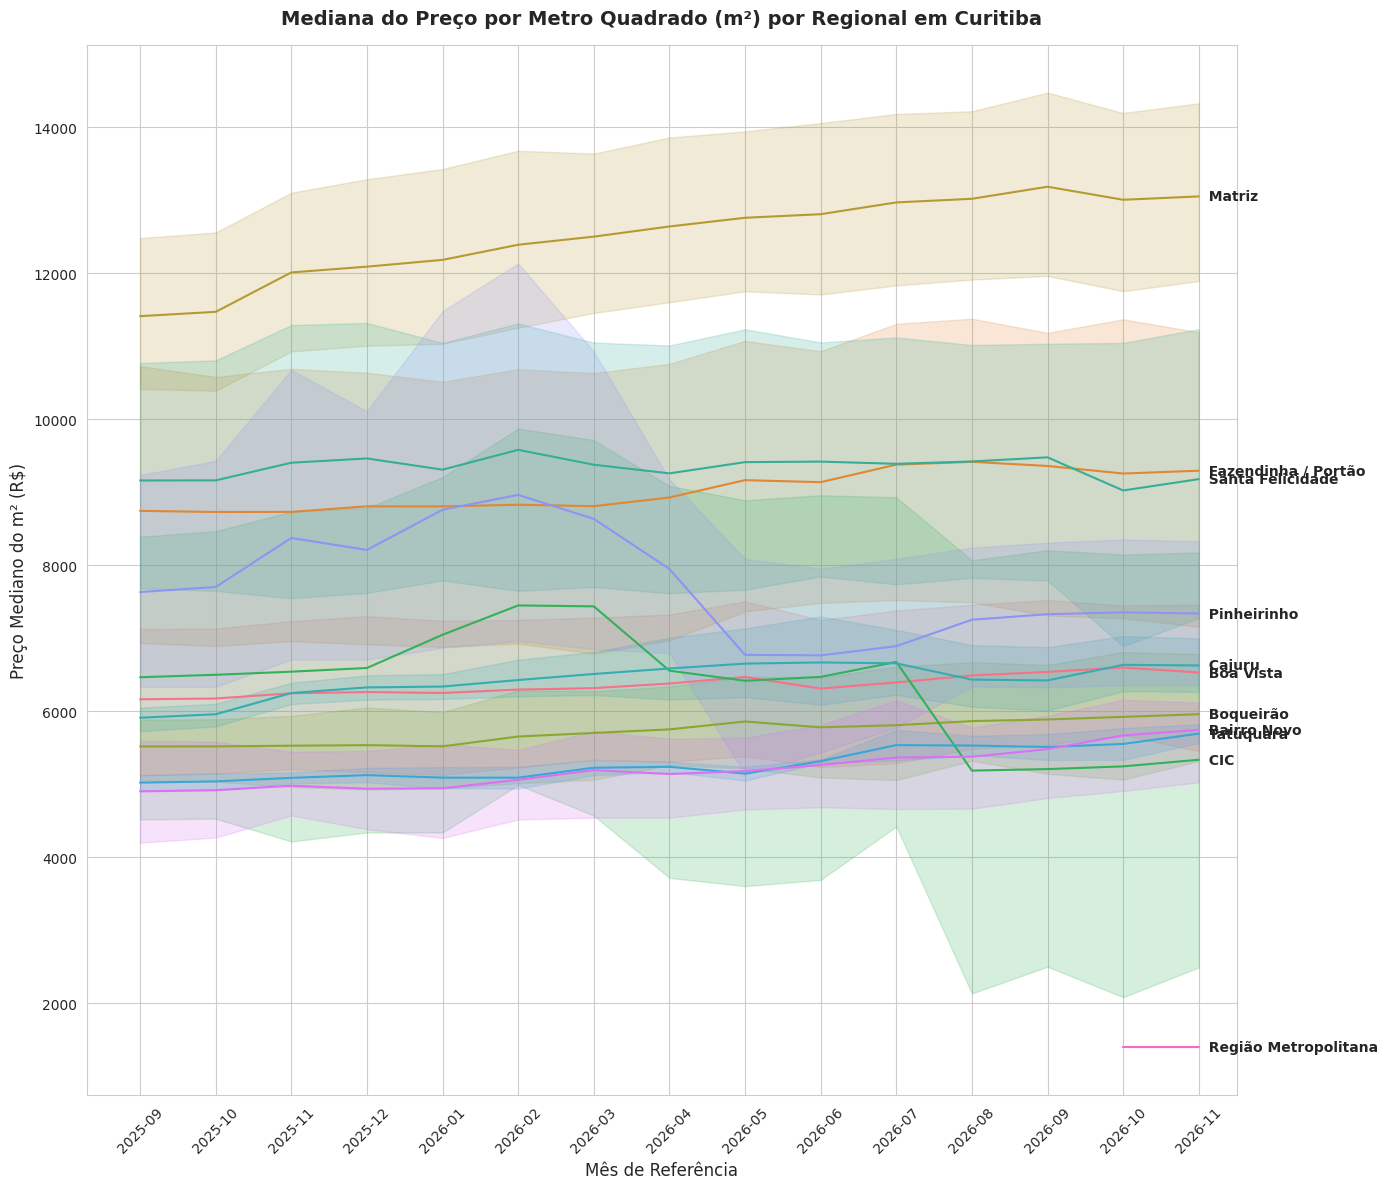

In [272]:

with sns.axes_style('whitegrid'):
  # Aumentamos um pouco a margem direita da figura para caberem os nomes dos bairros/regionais
  fig, ax = plt.subplots(figsize=(14, 12))

  # Plotamos as linhas sem exibir a legenda padrão do seaborn (legend=False)
  sns.lineplot(
      data=imoveis_df,
      y='mediana_m2',
      x='mes',
      hue='regional',
      ax=ax,
      legend=False
  )

  # Configuração do título e eixos
  ax.set_title('Mediana do Preço por Metro Quadrado (m²) por Regional em Curitiba', fontsize=14, fontweight='bold', pad=15)
  ax.set_xlabel('Mês de Referência', fontsize=12)
  ax.set_ylabel('Preço Mediano do m² (R$)', fontsize=12)

  # Rotacionar as datas do eixo X para melhor leitura
  plt.xticks(rotation=45)

  # Adicionar o nome da regional diretamente no final de cada linha
  # Ordenamos os meses para garantir que pegamos o último ponto cronológico de forma consistente
  meses_ordenados = sorted(imoveis_df['mes'].unique())
  ultimo_mes = meses_ordenados[-1]

  # Iteramos sobre cada regional para posicionar o texto
  for regional, df_reg in imoveis_df.groupby('regional'):
      # Filtra os dados da regional para o último mês disponível dela
      df_ultimo = df_reg[df_reg['mes'] == ultimo_mes]
      if not df_ultimo.empty:
          y_val = df_ultimo['mediana_m2'].mean() # Caso haja múltiplos registros, tiramos a média
          # Adiciona o texto ligeiramente deslocado para a direita do último ponto do eixo X
          ax.text(
              x=ultimo_mes,
              y=y_val,
              s=f'  {regional}',
              va='center',
              fontsize=10,
              fontweight='semibold'
          )

  # Ajusta o limite do eixo X para dar espaço para o texto não ser cortado
  ax.set_xlim(right=len(meses_ordenados) - 0.5)

  plt.tight_layout()
  plt.show()

## Bairros com valores maiores e menores

       mes  mediana_m2
0  2026-11      8105.0


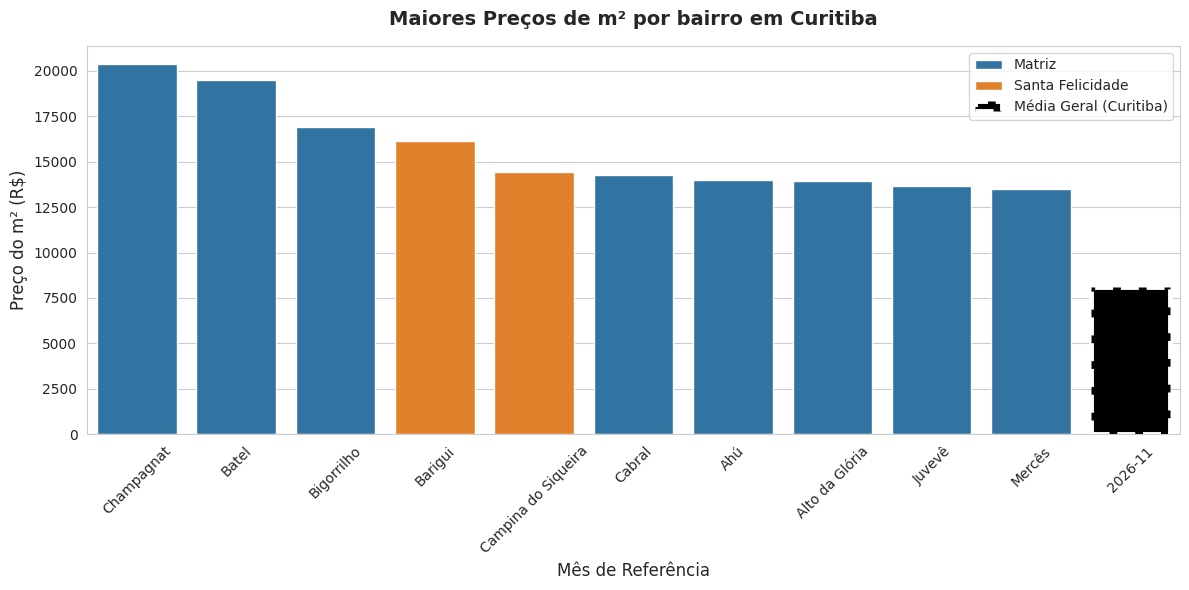

In [273]:
# Filtrar base com 10 maiores valores no último mês
ultimo_mes = imoveis_df.mes.max()
bairros_maiores = imoveis_df.loc[imoveis_df['mes'] == ultimo_mes].nlargest(10, 'mediana_m2')

# Plotar gráfico
with sns.axes_style('whitegrid'):
  # Aumentamos um pouco a margem direita da figura para caberem os nomes dos bairros/regionais
  fig, ax = plt.subplots(figsize=(12, 6))
  sns.barplot(
      data=bairros_maiores,
      y='mediana_m2',
      x='bairro',
      hue='regional',
      ax=ax,
      legend=True
  )

  # adicionar mediana entre os bairros de imoveis_df no último mês
  mediana_geral = imoveis_df.loc[imoveis_df['mes'] == ultimo_mes].groupby('mes').agg({'mediana_m2': 'median'}).reset_index()
  print(mediana_geral)
  sns.barplot(
      data=mediana_geral,
      y='mediana_m2',
      x='mes',
      ax=ax,
      color='black',
      linewidth=3.5,
      linestyle='--',
      label='Média Geral (Curitiba)'
  )

  # Configuração do título e eixos

  ax.set_title('Maiores Preços de m² por bairro em Curitiba', fontsize=14, fontweight='bold', pad=15)
  ax.set_xlabel('Mês de Referência', fontsize=12)
  ax.set_ylabel('Preço do m² (R$)', fontsize=12)
  plt.xticks(rotation=45)
  plt.tight_layout()
  plt.show()


       mes  mediana_m2
0  2026-11      8105.0


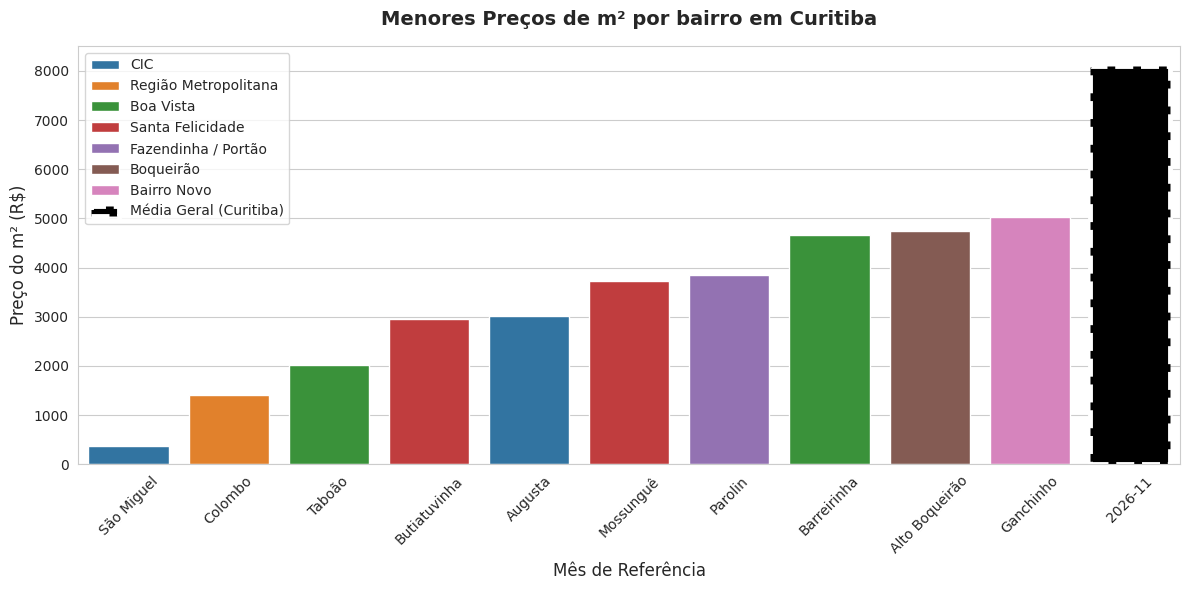

In [274]:
# Filtrar base com 10 menores valores no último mês
ultimo_mes = imoveis_df.mes.max()
bairros_menores = imoveis_df.loc[imoveis_df['mes'] == ultimo_mes].nsmallest(10, 'mediana_m2')

# Plotar gráfico
with sns.axes_style('whitegrid'):
  # Aumentamos um pouco a margem direita da figura para caberem os nomes dos bairros/regionais
  fig, ax = plt.subplots(figsize=(12, 6))
  sns.barplot(
      data=bairros_menores,
      y='mediana_m2',
      x='bairro',
      hue='regional',
      ax=ax,
      legend=True
  )

  # adicionar mediana entre os bairros de imoveis_df no último mês
  mediana_geral = imoveis_df.loc[imoveis_df['mes'] == ultimo_mes].groupby('mes').agg({'mediana_m2': 'median'}).reset_index()
  print(mediana_geral)
  sns.barplot(
      data=mediana_geral,
      y='mediana_m2',
      x='mes',
      ax=ax,
      color='black',
      linewidth=3.5,
      linestyle='--',
      label='Média Geral (Curitiba)'
  )

  # Configuração do título e eixos

  ax.set_title('Menores Preços de m² por bairro em Curitiba', fontsize=14, fontweight='bold', pad=15)
  ax.set_xlabel('Mês de Referência', fontsize=12)
  ax.set_ylabel('Preço do m² (R$)', fontsize=12)
  plt.xticks(rotation=45)
  plt.tight_layout()
  plt.show()


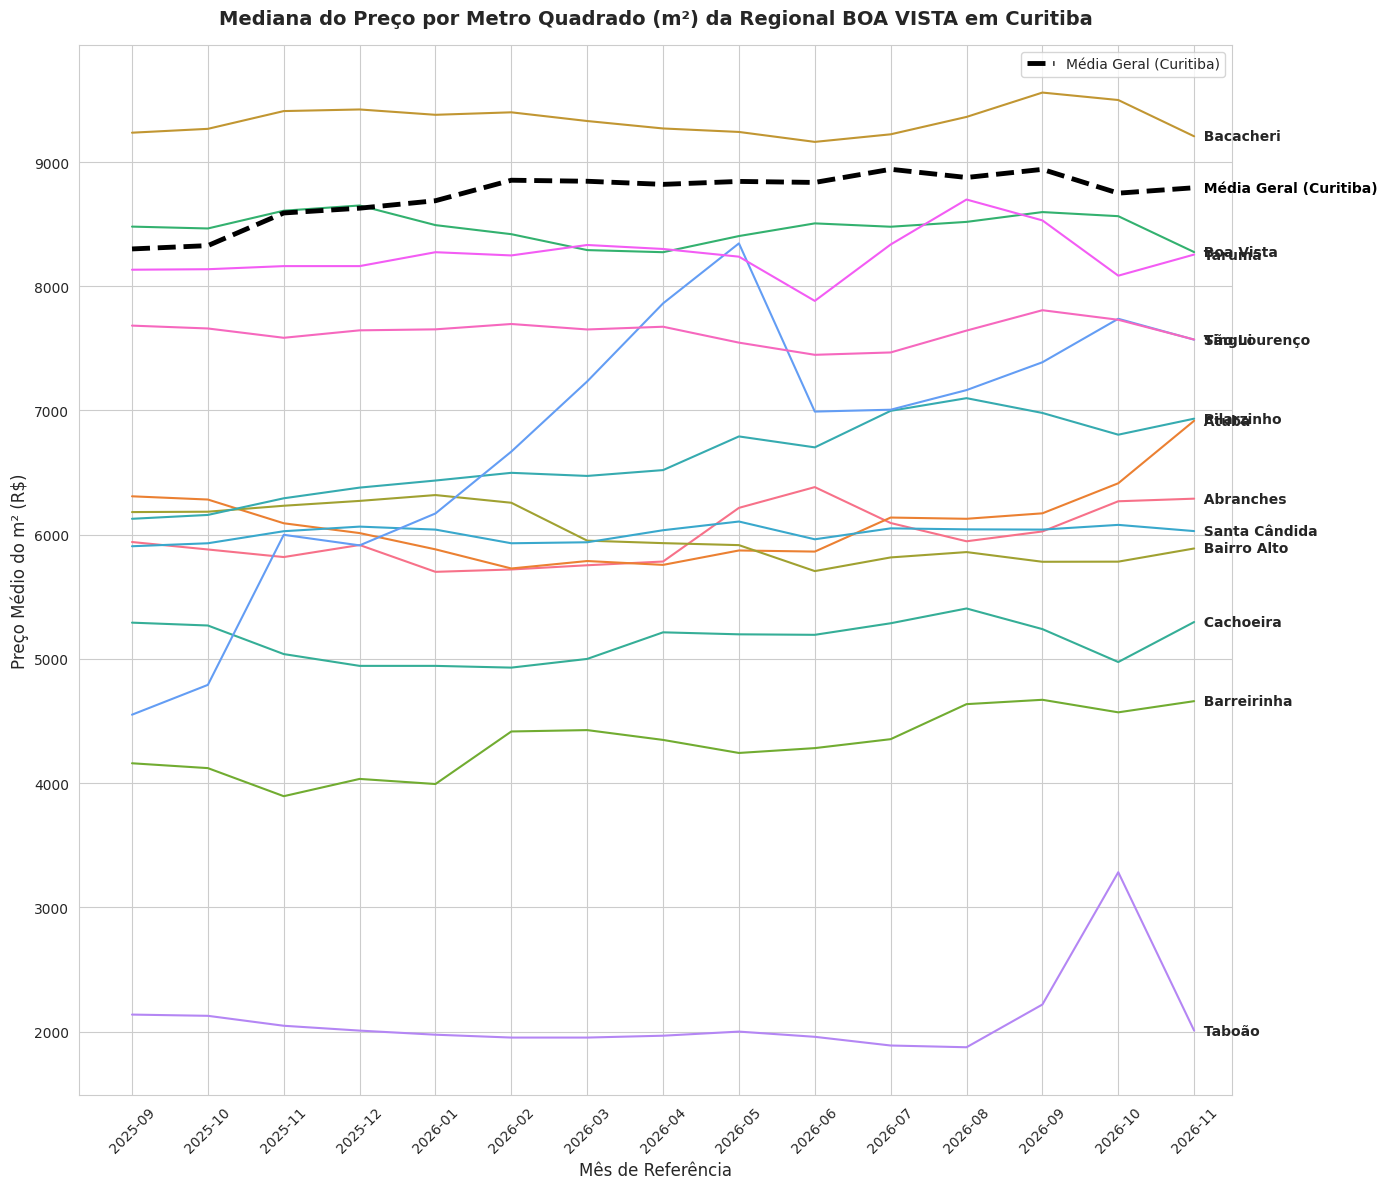

In [275]:
regional = 'Boa Vista' # @param ['Boa Vista', 'Matriz', 'Santa Felicidade', 'Cajuru', 'Boqueirão', 'Pinheirinho', 'Bairro Novo', 'Tatuquara', 'Fazendinha / Portão', 'CIC']

with sns.axes_style('whitegrid'):
  # Aumentamos um pouco a margem direita da figura para caberem os nomes dos bairros/regionais
  fig, ax = plt.subplots(figsize=(14, 12))

  # Filtramos usando imoveis_df['regional']
  df_filtrado = imoveis_df[imoveis_df['regional'] == regional]

  # Plotamos as linhas sem exibir a legenda padrão do seaborn (legend=False)
  sns.lineplot(
      data=df_filtrado,
      y='mediana_m2',
      x='mes',
      hue='bairro',
      ax=ax,
      legend=False
  )

  # Calcular e plotar a média geral de Curitiba (com base em todos os dados de venda do dataset)
  media_geral = imoveis_df.groupby('mes')['mediana_m2'].mean().reset_index()
  sns.lineplot(
      data=media_geral,
      y='mediana_m2',
      x='mes',
      ax=ax,
      color='black',
      linewidth=3.5,
      linestyle='--',
      label='Média Geral (Curitiba)'
  )

  # Configuração do título e eixos
  ax.set_title(f'Mediana do Preço por Metro Quadrado (m²) da Regional {regional.upper()} em Curitiba', fontsize=14, fontweight='bold', pad=15)
  ax.set_xlabel('Mês de Referência', fontsize=12)
  ax.set_ylabel('Preço Médio do m² (R$)', fontsize=12)

  # Rotacionar as datas do eixo X para melhor leitura
  plt.xticks(rotation=45)

  # Adicionar o nome do bairro diretamente no final de cada linha
  meses_ordenados = sorted(df_filtrado['mes'].unique())
  if meses_ordenados:
      ultimo_mes = meses_ordenados[-1]

      # Iteramos sobre cada bairro da regional filtrada
      for bairro, df_bairro in df_filtrado.groupby('bairro'):
          # Filtra os dados do bairro para o último mês disponível dele
          df_ultimo = df_bairro[df_bairro['mes'] == ultimo_mes]
          if not df_ultimo.empty:
              y_val = df_ultimo['mediana_m2'].mean()
              # Adiciona o nome do bairro real ao final da linha correspondente
              ax.text(
                  x=ultimo_mes,
                  y=y_val,
                  s=f'  {bairro}',
                  va='center',
                  fontsize=10,
                  fontweight='semibold'
              )

      # Adicionar o rótulo da linha de média geral ao final dela
      df_ultimo_geral = media_geral[media_geral['mes'] == ultimo_mes]
      if not df_ultimo_geral.empty:
          y_val_geral = df_ultimo_geral['mediana_m2'].mean()
          ax.text(
              x=ultimo_mes,
              y=y_val_geral,
              s='  Média Geral (Curitiba)',
              va='center',
              fontsize=10,
              fontweight='bold',
              color='black'
          )

      # Ajusta o limite do eixo X para dar espaço para o texto não ser cortado
      ax.set_xlim(right=len(meses_ordenados) - 0.5)

  plt.tight_layout()
  plt.show()

# Mostrar anúncios ativos